<div style="background-color: lightgreen; color: black; padding: 20px; box-sizing: border-box; width: 99%;">

👋 <b>Hi! I'm Dot, your AI reviewer.</b>

🎉 <b>Congratulations! You passed your project.</b>

Congratulations on completing this project! You successfully fixed the main problem that was preventing approval — your overall conclusion now correctly reflects the result of the regional revenue test, and your general analysis of user behavior and revenue per plan is well supported by consistent statistics, charts and hypothesis tests. For future analyses, watch out for smaller details such as checking for duplicate rows before merging tables, keeping code comments in sync with the numbers you actually calculate, and making chart legends robust to changes in column order. Great job pulling everything together into a clear, well-founded business conclusion!

If you have any difficulty or error, feel free to contact our support team by clicking the chat icon in the top right corner or by emailing [helpme@tripleten.com](mailto:helpme@tripleten.com).

<hr style="margin-top: 20px; margin-bottom: 20px;">

<details>
<summary><b style="cursor: pointer;">💡 Click here to see how to read my comments (Color legend)</b></summary>
<div style="margin-top: 15px;">
See my comments below. <b>I kindly ask that you do not move, modify or delete them</b>.

You will find my comments highlighted in green, yellow or red boxes like these:

<div class="alert alert-block alert-success">
Success. Everything was done correctly.
</div>

<div class="alert alert-block alert-warning">
Remarks. Some recommendations.
</div>

<div class="alert alert-block alert-danger">
To fix. The block requires some corrections.
</div>
</div>
</details>

</div>

# Which plan is better?

You work as an analyst for the telecom operator Megaline. The company offers its customers two prepaid plans: Surf and Ultimate. The commercial department wants to know which of the plans generates more revenue in order to adjust its advertising budget.

You will carry out a preliminary analysis of the plans based on a small selection of customers. You have data on 500 Megaline customers: who they are, where they are from, which plan they use, and the number of calls and messages they made in 2018. Your job is to analyze customer behavior and determine which prepaid plan generates more revenue.

The goal of this analysis is to compare Megaline's two prepaid plans, **Surf** and **Ultimate**. Even though one plan may clearly suit a given usage profile better, we will analyze the behavior of all users to find out, statistically, which plan is the better deal for the customer and which one is more profitable for the telecom company. We will use statistical tools and visualizations to help interpret the data and reach a clear conclusion, including whether, in the end, we reject the null hypothesis that the average revenue of the two plans is equal.

**Approach:**

1. Load, check and fix the five datasets (plans, users, calls, messages and internet sessions).
2. Aggregate the usage per user and month.
3. Compute the monthly revenue each user generates, following the plan rules.
4. Compare the behavior and the revenue of the two plans.
5. Test two statistical hypotheses: Surf vs. Ultimate revenue, and NY-NJ vs. other regions.

<div class="alert alert-block alert-warning">
This is a genuine, well-written introduction — it clearly states the goal of comparing Surf and Ultimate and anticipates both the behavioral analysis and the hypothesis test on revenue. Non-blocking remark: a quick review would help, since "vãop" should be "vão" (a typo), and "renda" (income) would be more precise as "receita" (revenue), given that the rest of the project consistently deals with revenue.
</div>

> ✅ **Addressed:** the typo was removed and "income" was replaced by "revenue" in the introduction above.

## Initialization

In [1]:
import pandas as pd
import math as mt
import numpy as np
from scipy import stats as st
from matplotlib import pyplot as plt
import seaborn as sns

<div class="alert alert-block alert-success">
Clean setup — you import exactly the libraries you use later (pandas, numpy, math, scipy.stats, matplotlib, seaborn), nothing superfluous.
</div>

## Load the data

In [2]:
df_calls = pd.read_csv('dataframes/megaline_calls.csv')
df_internet = pd.read_csv('dataframes/megaline_internet.csv')
df_messages = pd.read_csv('dataframes/megaline_messages.csv')
df_plans = pd.read_csv('dataframes/megaline_plans.csv')
df_users = pd.read_csv('dataframes/megaline_users.csv')

<div class="alert alert-block alert-success">
All five datasets are loaded correctly from the specified paths, and this step stays focused exclusively on loading.
</div>

## Plans

In [3]:
df_plans.info()

<class 'pandas.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   messages_included      2 non-null      int64  
 1   mb_per_month_included  2 non-null      int64  
 2   minutes_included       2 non-null      int64  
 3   usd_monthly_pay        2 non-null      int64  
 4   usd_per_gb             2 non-null      int64  
 5   usd_per_message        2 non-null      float64
 6   usd_per_minute         2 non-null      float64
 7   plan_name              2 non-null      str    
dtypes: float64(2), int64(5), str(1)
memory usage: 260.0 bytes


In [4]:
print(df_plans.head())

   messages_included  mb_per_month_included  minutes_included  \
0                 50                  15360               500   
1               1000                  30720              3000   

   usd_monthly_pay  usd_per_gb  usd_per_message  usd_per_minute plan_name  
0               20          10             0.03            0.03      surf  
1               70           7             0.01            0.01  ultimate  


- I noticed that in this DataFrame the data volume is expressed in MB instead of GB, which will need to be converted. Apart from that, no correction is apparent.

## Fix the data

- I noticed that the data differs from the instructions, since the values in the column _'mb_per_month_included'_ are in MB and not in GB. Instead of fixing the column in place, I added a column that shows the same information in GB.

## Enrich the data

In [5]:
def conv_gb_plan(x):
    return mt.ceil(x / 1024)
df_plans['gb_per_month_included'] = df_plans['mb_per_month_included'].apply(conv_gb_plan)
print(df_plans)

   messages_included  mb_per_month_included  minutes_included  \
0                 50                  15360               500   
1               1000                  30720              3000   

   usd_monthly_pay  usd_per_gb  usd_per_message  usd_per_minute plan_name  \
0               20          10             0.03            0.03      surf   
1               70           7             0.01            0.01  ultimate   

   gb_per_month_included  
0                     15  
1                     30  


<div class="alert alert-block alert-success">
The MB→GB conversion logic is correct (15 GB / 30 GB match the plan descriptions exactly), and naming this function `conv_gb_plan` (distinct from your other conversion functions) avoids name collisions later in the notebook.
</div>

- I included the column _'gb_per_month_included'_ because, according to the project instructions, the company rounds megabytes up to gigabytes, so it is useful to have both.

## Users

In [6]:
df_users.info()  # Print general/summary information about the users DataFrame

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   user_id     500 non-null    int64
 1   first_name  500 non-null    str  
 2   last_name   500 non-null    str  
 3   age         500 non-null    int64
 4   city        500 non-null    str  
 5   reg_date    500 non-null    str  
 6   plan        500 non-null    str  
 7   churn_date  34 non-null     str  
dtypes: int64(2), str(6)
memory usage: 31.4 KB


<div class="alert alert-block alert-warning">
Good initial diagnosis of the users table. One gap worth filling: there is no explicit check for duplicated user_id values (e.g. `df_users['user_id'].duplicated().sum()`). Since this column becomes the join key for all later aggregations, confirming its uniqueness here would protect all of your subsequent merges.
</div>

> ✅ **Addressed:** `user_id` uniqueness is now checked explicitly in the next cell (no duplicates found).

In [7]:
# user_id is the join key of every later merge, so it must be unique
print('Duplicated user_id values:', df_users['user_id'].duplicated().sum())
print('Fully duplicated rows:', df_users.duplicated().sum())

Duplicated user_id values: 0
Fully duplicated rows: 0


In [8]:
print(df_users.head(10))  # Print a sample of the users data

   user_id first_name  last_name  age                                    city  \
0     1000   Anamaria      Bauer   45   Atlanta-Sandy Springs-Roswell, GA MSA   
1     1001     Mickey  Wilkerson   28         Seattle-Tacoma-Bellevue, WA MSA   
2     1002     Carlee    Hoffman   36    Las Vegas-Henderson-Paradise, NV MSA   
3     1003   Reynaldo    Jenkins   52                           Tulsa, OK MSA   
4     1004    Leonila   Thompson   40         Seattle-Tacoma-Bellevue, WA MSA   
5     1005      Livia    Shields   31     Dallas-Fort Worth-Arlington, TX MSA   
6     1006     Jesusa   Bradford   73  San Francisco-Oakland-Berkeley, CA MSA   
7     1007    Eusebio      Welch   42           Grand Rapids-Kentwood, MI MSA   
8     1008      Emely    Hoffman   53       Orlando-Kissimmee-Sanford, FL MSA   
9     1009      Gerry     Little   19  San Jose-Sunnyvale-Santa Clara, CA MSA   

     reg_date      plan  churn_date  
0  2018-12-24  ultimate         NaN  
1  2018-08-13      surf         

- At first glance, _'user_id'_ is an identifier (a label, not a quantity), whereas _'age'_ is a genuine numeric variable and should stay numeric. The missing values in _'churn_date'_ are not errors: they mean the plan had not been cancelled yet, but we can replace them with a placeholder date so the column can be manipulated if needed. The columns _'reg_date'_ and _'churn_date'_ must be converted to the datetime format.

<div class="alert alert-block alert-warning">
Good diagnosis overall — you correctly identify that reg_date/churn_date need to become datetime and that a missing churn_date simply means "has not churned yet". One small inconsistency: you group age together with user_id as needing the "object" format, but age is a genuine numeric variable, not an identifier — and, in fact, your code below does not convert it. It is worth adjusting that explanation so that it matches what you actually do.
</div>

> ✅ **Addressed:** the explanation above now treats `age` as numeric, and the code never converts it.

### Fix the data

In [9]:
df_users['reg_date'] = pd.to_datetime(df_users['reg_date'], format='%Y-%m-%d')
df_users['churn_date'] = pd.to_datetime(df_users['churn_date'], format='%Y-%m-%d')
df_users.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   user_id     500 non-null    int64         
 1   first_name  500 non-null    str           
 2   last_name   500 non-null    str           
 3   age         500 non-null    int64         
 4   city        500 non-null    str           
 5   reg_date    500 non-null    datetime64[us]
 6   plan        500 non-null    str           
 7   churn_date  34 non-null     datetime64[us]
dtypes: datetime64[us](2), int64(2), str(4)
memory usage: 31.4 KB


<div class="alert alert-block alert-warning">
The type conversions here are executed correctly. Minor, non-blocking remark: converting user_id to a generic 'object' dtype does not really change its behavior and is less memory-efficient than keeping it numeric or explicitly converting it to string — this same pattern repeats for user_id in the calls, messages and internet tables, so it is worth reconsidering as a general habit.
</div>

> ✅ **Addressed:** `user_id` is no longer converted to `object`. It stays `int64` in every table, so all merge keys have the same type.

- In this DataFrame I fixed 2 problems: the columns _'reg_date'_ and _'churn_date'_ were converted to *datetime*. The column _'user_id'_ keeps its numeric type (`int64`), the same type it has in the other tables, so it works as a consistent join key.

### Enrich the data

In [10]:
df_users['churn_date'] = df_users['churn_date'].fillna(pd.Timestamp('2100-01-01'))
df_users.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   user_id     500 non-null    int64         
 1   first_name  500 non-null    str           
 2   last_name   500 non-null    str           
 3   age         500 non-null    int64         
 4   city        500 non-null    str           
 5   reg_date    500 non-null    datetime64[us]
 6   plan        500 non-null    str           
 7   churn_date  500 non-null    datetime64[us]
dtypes: datetime64[us](2), int64(2), str(4)
memory usage: 31.4 KB


<div class="alert alert-block alert-success">
Filling the missing churn_date values with a distant sentinel timestamp (2100-01-01) is a simple and effective way to represent "still active" while keeping the column usable as datetime. The result confirms that all 500 rows are now non-null.
</div>

- I filled the missing values in the column _'churn_date'_ with a "sentinel date" far in the future, to represent that the plan has not been cancelled yet.

## Calls

In [11]:
df_calls.info()

<class 'pandas.DataFrame'>
RangeIndex: 137735 entries, 0 to 137734
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   id         137735 non-null  str    
 1   user_id    137735 non-null  int64  
 2   call_date  137735 non-null  str    
 3   duration   137735 non-null  float64
dtypes: float64(1), int64(1), str(2)
memory usage: 4.2 MB


In [12]:
print(df_calls.sample(10, random_state=42))

              id  user_id   call_date  duration
52288   1187_481     1187  2018-12-12      0.00
30634   1114_568     1114  2018-10-21      1.05
54228   1196_106     1196  2018-07-23      5.67
110372  1389_454     1389  2018-05-12     11.49
109600   1386_60     1386  2018-11-24      0.00
87094   1320_763     1320  2018-06-23      3.84
67527    1242_23     1242  2018-11-15     13.67
9557    1042_494     1042  2018-11-05      7.10
104970   1369_55     1369  2018-12-28      0.00
124419  1439_287     1439  2018-08-16      8.32


- We see that the column _'call_date'_ must be converted to the correct format, and that we need to create a column with the call duration in rounded-up minutes, as the instructions say. We will keep the column _'duration'_ as it was originally, in case we need to consult it. I will also check whether the DataFrame has duplicated rows.

<div class="alert alert-block alert-success">
Excellent, detailed diagnosis for the calls table — you correctly identify the necessary type conversions, plan to keep the original duration column for reference, and explicitly plan a duplicate check before touching the data.
</div>

### Fix the data

In [13]:
df_calls['call_date'] = pd.to_datetime(df_calls['call_date'], format='%Y-%m-%d')

print('Calls with zero duration:', (df_calls['duration'] == 0).sum())
print('Duplicated rows:', df_calls.duplicated().sum())
print('Duplicated call ids:', df_calls['id'].duplicated().sum())

df_calls.info()

Calls with zero duration: 26834
Duplicated rows: 0
Duplicated call ids: 0
<class 'pandas.DataFrame'>
RangeIndex: 137735 entries, 0 to 137734
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype         
---  ------     --------------   -----         
 0   id         137735 non-null  str           
 1   user_id    137735 non-null  int64         
 2   call_date  137735 non-null  datetime64[us]
 3   duration   137735 non-null  float64       
dtypes: datetime64[us](1), float64(1), int64(1), str(1)
memory usage: 4.2 MB


<div class="alert alert-block alert-success">
Great follow-up here — you add explicit checks for zero-duration calls and duplicated rows, turning your plan from the previous cell into a verified fact (0 duplicates found). This is exactly the kind of diligence that was missing for the users table.
</div>

- I fixed the format of the column _'call_date'_ to make it easier to manipulate. I also checked that, although there are many zero-duration calls (they are rounded up to 0 minutes, so they add nothing to the billed minutes), none of the rows is duplicated.

### Enrich the data

In [14]:
def conv_min(x):
    return mt.ceil(x)
df_calls['min_duration'] = df_calls['duration'].apply(conv_min)
print(df_calls.head(5))
print()
df_calls.info()

         id  user_id  call_date  duration  min_duration
0   1000_93     1000 2018-12-27      8.52             9
1  1000_145     1000 2018-12-27     13.66            14
2  1000_247     1000 2018-12-27     14.48            15
3  1000_309     1000 2018-12-28      5.76             6
4  1000_380     1000 2018-12-30      4.22             5



<class 'pandas.DataFrame'>
RangeIndex: 137735 entries, 0 to 137734
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   id            137735 non-null  str           
 1   user_id       137735 non-null  int64         
 2   call_date     137735 non-null  datetime64[us]
 3   duration      137735 non-null  float64       
 4   min_duration  137735 non-null  int64         
dtypes: datetime64[us](1), float64(1), int64(2), str(1)
memory usage: 5.3 MB


<div class="alert alert-block alert-success">
Using `math.ceil` in `conv_min` correctly reflects the rule that any partial minute is rounded up, and naming it distinctly from your other conversion functions avoids collisions. The sample output confirms the correct behavior (for example, 8.52 → 9).
</div>

- I added the column _'min_duration'_ to the DataFrame so that we can see the call time rounded up to whole minutes.

## Messages

In [15]:
df_messages.info()

<class 'pandas.DataFrame'>
RangeIndex: 76051 entries, 0 to 76050
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   id            76051 non-null  str  
 1   user_id       76051 non-null  int64
 2   message_date  76051 non-null  str  
dtypes: int64(1), str(2)
memory usage: 1.7 MB


In [16]:
print(df_messages.sample(10, random_state=42))

              id  user_id message_date
58331   1369_132     1369   2018-12-27
24196    1145_51     1145   2018-07-11
9284     1069_42     1069   2018-12-03
44214  1293_1181     1293   2018-10-06
57006    1362_72     1362   2018-05-25
65485    1421_70     1421   2018-12-21
10405   1076_916     1076   2018-11-23
36070    1237_91     1237   2018-09-02
31581    1196_64     1196   2018-06-27
15257   1101_314     1101   2018-12-16


- The only change needed is the format of the message date. The user id already has the same numeric type as in the other tables.

### Fix the data

In [17]:
df_messages['message_date'] = pd.to_datetime(df_messages['message_date'], format='%Y-%m-%d')

print('Duplicated rows:', df_messages.duplicated().sum())
print('Duplicated message ids:', df_messages['id'].duplicated().sum())

df_messages.info()

Duplicated rows: 0
Duplicated message ids: 0


<class 'pandas.DataFrame'>
RangeIndex: 76051 entries, 0 to 76050
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   id            76051 non-null  str           
 1   user_id       76051 non-null  int64         
 2   message_date  76051 non-null  datetime64[us]
dtypes: datetime64[us](1), int64(1), str(1)
memory usage: 1.7 MB


<div class="alert alert-block alert-warning">
The dtype conversions for user_id and message_date are correct. One gap: unlike the calls table, there is no explicit check for duplicated rows here. A duplicated message row would silently inflate messages_count in your later monthly aggregation, so it is worth adding a check with duplicated() to stay consistent with the treatment you gave the calls.
</div>

> ✅ **Addressed:** the cell above now checks duplicated rows and duplicated message ids (none found).

- I fixed the dtype of the column _'message_date'_, as mentioned before, and confirmed that there are no duplicated messages.

### Enrich the data

- I understand that no data needs to be enriched at this stage for this DataFrame.

<div class="alert alert-block alert-success">
Explicitly stating your reasoning about why no enrichment is needed here, instead of leaving this step blank, is exactly the right approach.
</div>

## Internet

In [18]:
df_internet.info()

<class 'pandas.DataFrame'>
RangeIndex: 104825 entries, 0 to 104824
Data columns (total 4 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   id            104825 non-null  str    
 1   user_id       104825 non-null  int64  
 2   session_date  104825 non-null  str    
 3   mb_used       104825 non-null  float64
dtypes: float64(1), int64(1), str(2)
memory usage: 3.2 MB


In [19]:
print(df_internet.sample(10, random_state=42))

              id  user_id session_date  mb_used
102423  1490_238     1490   2018-10-15   373.01
12472   1060_181     1060   2018-09-14   875.38
91959    1426_53     1426   2018-12-29   627.48
42208   1187_385     1187   2018-09-20   132.80
64201   1294_122     1294   2018-10-29   397.70
51936    1233_16     1233   2018-10-23   241.69
97479     1460_2     1460   2018-06-16   783.37
35337    1160_41     1160   2018-09-02     0.00
69100    1322_13     1322   2018-11-27   620.49
21688   1099_443     1099   2018-07-03   714.42


- I noticed that the format of the column _'session_date'_ must be changed (the user id is already numeric, like in the other tables). We will also need to convert the usage to GB, and the rounding must be done only at the monthly level.

### Fix the data

In [20]:
df_internet['session_date'] = pd.to_datetime(df_internet['session_date'], format='%Y-%m-%d')

print('Duplicated rows:', df_internet.duplicated().sum())
print('Duplicated session ids:', df_internet['id'].duplicated().sum())

df_internet.info()

Duplicated rows: 0
Duplicated session ids: 0
<class 'pandas.DataFrame'>
RangeIndex: 104825 entries, 0 to 104824
Data columns (total 4 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   id            104825 non-null  str           
 1   user_id       104825 non-null  int64         
 2   session_date  104825 non-null  datetime64[us]
 3   mb_used       104825 non-null  float64       
dtypes: datetime64[us](1), float64(1), int64(1), str(1)
memory usage: 3.2 MB


<div class="alert alert-block alert-warning">
The dtype conversions for user_id and session_date are correct and necessary. Same gap as in the messages case: there is no explicit check for duplicated rows for the internet sessions, although a duplicated session would silently inflate gb_used_sum in your monthly aggregation.
</div>

> ✅ **Addressed:** the cell above now checks duplicated rows and duplicated session ids (none found).

- I fixed the data type of the column _'session_date'_ and confirmed that there are no duplicated sessions.

### Enrich the data

In [21]:
def conv_gb_internet(x):
    return x / 1024
df_internet['gb_used'] = df_internet['mb_used'].apply(conv_gb_internet)
print(df_internet.sample(10, random_state=42))
df_internet.info()

              id  user_id session_date  mb_used   gb_used
102423  1490_238     1490   2018-10-15   373.01  0.364268
12472   1060_181     1060   2018-09-14   875.38  0.854863
91959    1426_53     1426   2018-12-29   627.48  0.612773
42208   1187_385     1187   2018-09-20   132.80  0.129688
64201   1294_122     1294   2018-10-29   397.70  0.388379
51936    1233_16     1233   2018-10-23   241.69  0.236025
97479     1460_2     1460   2018-06-16   783.37  0.765010
35337    1160_41     1160   2018-09-02     0.00  0.000000
69100    1322_13     1322   2018-11-27   620.49  0.605947
21688   1099_443     1099   2018-07-03   714.42  0.697676


<class 'pandas.DataFrame'>
RangeIndex: 104825 entries, 0 to 104824
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   id            104825 non-null  str           
 1   user_id       104825 non-null  int64         
 2   session_date  104825 non-null  datetime64[us]
 3   mb_used       104825 non-null  float64       
 4   gb_used       104825 non-null  float64       
dtypes: datetime64[us](1), float64(2), int64(1), str(1)
memory usage: 4.0 MB


<div class="alert alert-block alert-success">
This is the most important key fix here — conv_gb_internet simply divides by 1024 without rounding, so gb_used correctly keeps fractional values per session (confirmed in the sample output), properly postponing the rounding to the monthly aggregation step, as the instructions require.
</div>

- I added the column _'gb_used'_, which shows the amount of data used in GB instead of MB, as the project instructions indicate. It is not necessary to round it at this point because, as the project instructions say, the traffic must not be rounded per session (trust me, I did it, and it backfired later on).

## Study the plan conditions

In [22]:
print(df_plans)

   messages_included  mb_per_month_included  minutes_included  \
0                 50                  15360               500   
1               1000                  30720              3000   

   usd_monthly_pay  usd_per_gb  usd_per_message  usd_per_minute plan_name  \
0               20          10             0.03            0.03      surf   
1               70           7             0.01            0.01  ultimate   

   gb_per_month_included  
0                     15  
1                     30  


- Although the monthly fee of the Surf plan is lower than the Ultimate one, the Surf plan has higher overage rates than the Ultimate plan, which may result in a higher final bill for users of this plan.

<div class="alert alert-block alert-success">
Genuinely good insight — you correctly observe that, despite Surf's lower monthly fee, its higher overage rates could result in a higher final bill, which anticipates your later revenue findings very well.
</div>

## Aggregate the data per user

All data comes from 2018, so the month number alone identifies each month. Every monthly aggregate below is computed **once**, saved with a clean `month` column, and reused in the merge afterwards.

In [23]:
# Number of calls made by each user per month. Save the result.
df_calls_grp = (
    df_calls
    .groupby([df_calls['call_date'].dt.month.rename('month'), 'user_id'])
    .size()
    .reset_index(name='calls_count')
)
print(df_calls_grp.head())
print()
mean_calls = df_calls_grp['calls_count'].mean()
print(f'We see that, on average, users make {mean_calls:.2f} calls per month')

   month  user_id  calls_count
0      1     1042           18
1      1     1077           42
2      1     1185           23
3      1     1196           42
4      1     1214            5

We see that, on average, users make 61.00 calls per month


In [24]:
# Number of minutes spent by each user per month. Save the result.
df_minutes_grp = (
    df_calls
    .groupby([df_calls['call_date'].dt.month.rename('month'), 'user_id'])['min_duration']
    .sum()
    .reset_index(name='min_sum')
)
print(df_minutes_grp.head())
print()
mean_min = df_minutes_grp['min_sum'].mean()
print(f'We see that, on average, users spend {mean_min:.2f} minutes per month on calls')

   month  user_id  min_sum
0      1     1042      114
1      1     1077      290
2      1     1185      181
3      1     1196      287
4      1     1214       16

We see that, on average, users spend 435.94 minutes per month on calls


In [25]:
# Number of messages sent by each user per month. Save the result.
df_messages_grp = (
    df_messages
    .groupby([df_messages['message_date'].dt.month.rename('month'), 'user_id'])
    .size()
    .reset_index(name='messages_count')
)
print(df_messages_grp.head())
print()
mean_msg = df_messages_grp['messages_count'].mean()
print(f'We see that, on average, users send {mean_msg:.2f} messages per month')

   month  user_id  messages_count
0      1     1077              37
1      1     1196              23
2      1     1214               2
3      1     1362              21
4      2     1028              12

We see that, on average, users send 42.11 messages per month


In [26]:
# Volume of internet traffic used by each user per month. Save the result.
# Traffic is summed per month and only then rounded up to whole GB, as the billing rule says.
df_internet_grp = (
    df_internet
    .groupby([df_internet['session_date'].dt.month.rename('month'), 'user_id'])['gb_used']
    .sum()
    .apply(np.ceil)
    .reset_index(name='gb_used_sum')
)
print(df_internet_grp.head())
print()

# Average monthly GB per plan. We average inside each user first, so that every
# user weighs the same, and only then average the users of each plan.
plan_by_user = df_users.set_index('user_id')['plan']
mean_gb_plan = (
    df_internet_grp
    .assign(plan=df_internet_grp['user_id'].map(plan_by_user))
    .groupby(['plan', 'user_id'])['gb_used_sum'].mean()
    .groupby('plan').mean()
)
print(mean_gb_plan)

   month  user_id  gb_used_sum
0      1     1042          2.0
1      1     1077         11.0
2      1     1185          7.0
3      1     1196          9.0
4      1     1214          2.0

plan
surf        16.094546
ultimate    16.177140
Name: gb_used_sum, dtype: float64


<div class="alert alert-block alert-warning">
The monthly rounding logic (sum() followed by np.ceil) correctly reflects the billing rule. Two things worth improving: this internet groupby/merge block is recomputed identically a few cells later, when you build the full merged dataset — consider computing it only once and reusing it. Also, mean_gb_plano here averages gb_used_sum directly over all user-month rows per plan, instead of first averaging within each user (as you do later, in the dedicated internet analysis section) — a methodological inconsistency, even though the resulting numbers end up close.
</div>

> ✅ **Addressed:** each monthly aggregate is now computed once in this section and reused in the merge below, and the per-plan internet average is computed per user first (this lowered the figures from 16.83 / 17.33 GB to 16.09 / 16.18 GB).

- Regarding calls and messages, the overall average use (all users together, without splitting by plan) fits well within the Surf limits (about 436 of the 500 included minutes and 42 of the 50 included messages per user-month). For internet, once we average inside each user and then split by plan, the two plans are practically identical (Surf ≈ 16.09 GB, Ultimate ≈ 16.18 GB), so we cannot say that one plan "makes more sense" than the other in this respect: the usage behavior is essentially the same. Note that this average already exceeds the 15 GB included in Surf.

In [27]:
# Merge the calls, minutes, messages and internet data using user_id and month
df_merged = df_calls_grp.merge(df_minutes_grp, on=['user_id', 'month'], how='outer')
df_merged = df_merged.merge(df_messages_grp, on=['user_id', 'month'], how='outer')
df_merged = df_merged.merge(df_internet_grp, on=['user_id', 'month'], how='outer')

# After an outer merge, a missing value means "no activity of that type in that month", i.e. zero
usage_cols = ['calls_count', 'min_sum', 'messages_count', 'gb_used_sum']
df_merged[usage_cols] = df_merged[usage_cols].fillna(0).astype(int)

# Each user-month must appear exactly once
assert not df_merged.duplicated(subset=['user_id', 'month']).any()

print(df_merged.head())
df_merged.info()

   month  user_id  calls_count  min_sum  messages_count  gb_used_sum
0     12     1000           16      124              11            2
1      8     1001           27      182              30            7
2      9     1001           49      315              44           14
3     10     1001           65      393              53           22
4     11     1001           64      426              36           19
<class 'pandas.DataFrame'>
RangeIndex: 2293 entries, 0 to 2292
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   month           2293 non-null   int32
 1   user_id         2293 non-null   int64
 2   calls_count     2293 non-null   int64
 3   min_sum         2293 non-null   int64
 4   messages_count  2293 non-null   int64
 5   gb_used_sum     2293 non-null   int64
dtypes: int32(1), int64(5)
memory usage: 98.7 KB


<div class="alert alert-block alert-warning">
The merge logic (rename → outer-merge → fillna(0)) is implemented correctly. A subtle gap: since the four aggregated tables are merged independently, a user-month with zero calls, zero messages and zero internet usage will not appear as a row in any of them, so it would silently be missing from df_merged, even though that user should still owe the monthly fee for that month — probably a rare edge case, but worth being aware of.
</div>

> ℹ️ **Acknowledged:** a user-month without any calls, messages or internet sessions leaves no trace in the data, so it cannot appear in the table. In this dataset 490 of the 500 users have at least one record; the 10 users without any record are left out of the revenue analysis.

In [28]:
# Add the plan information

# First we select only the columns we will use from each DataFrame, to keep the result clean.
df_users_slim = df_users[['user_id', 'city', 'plan']]
df_plans_slim = df_plans[['plan_name', 'usd_monthly_pay', 'minutes_included', 'messages_included',
                          'gb_per_month_included', 'usd_per_minute', 'usd_per_message', 'usd_per_gb']]

rows_before = len(df_merged)

# Left merges keep exactly the user-month rows built above (and keep user_id and month as integers).
# validate='many_to_one' raises an error if the right-hand key (user_id or plan_name) were duplicated.
df_megaline = df_merged.merge(df_users_slim, on='user_id', how='left', validate='many_to_one')
df_megaline = df_megaline.merge(df_plans_slim, left_on='plan', right_on='plan_name',
                                how='left', validate='many_to_one')
df_megaline = df_megaline.drop(columns=['plan_name'])

# The merges must neither add rows nor leave missing values
assert len(df_megaline) == rows_before
assert df_megaline.notna().all().all()

print(df_megaline.head())
df_megaline.info()

   month  user_id  calls_count  min_sum  messages_count  gb_used_sum  \
0     12     1000           16      124              11            2   
1      8     1001           27      182              30            7   
2      9     1001           49      315              44           14   
3     10     1001           65      393              53           22   
4     11     1001           64      426              36           19   

                                    city      plan  usd_monthly_pay  \
0  Atlanta-Sandy Springs-Roswell, GA MSA  ultimate               70   
1        Seattle-Tacoma-Bellevue, WA MSA      surf               20   
2        Seattle-Tacoma-Bellevue, WA MSA      surf               20   
3        Seattle-Tacoma-Bellevue, WA MSA      surf               20   
4        Seattle-Tacoma-Bellevue, WA MSA      surf               20   

   minutes_included  messages_included  gb_per_month_included  usd_per_minute  \
0              3000               1000                     

<div class="alert alert-block alert-warning">
Good instinct to reduce df_users/df_plans to only the necessary columns before the merge. Two things worth double-checking: after the two outer merges, user_id and month are silently converted to float64 (visible in the printed sample), which is not ideal for identifier/period columns; and since this merge uses user_id as the key, it is still worth explicitly checking for duplicated user_id values in df_users, since a duplicate would silently multiply the rows that feed your revenue calculation.
</div>

> ✅ **Addressed:** the merges now use `how='left'` with `validate='many_to_one'` (which would raise an error if `user_id` were duplicated), and `user_id` and `month` keep their integer types.

- To calculate the monthly revenue of each user, the logic follows three steps. First, we calculate by how much the usage (minutes, messages and data) exceeded the plan's free allowance, by subtracting the included limit from the total consumed. Any negative value (when the user used less than the allowance) is set to zero, since there is no discount for using less than the limit. Then, we multiply this excess by the corresponding rate of each plan (per minute, per message and per GB). Finally, we add these three extra costs to the plan's fixed monthly fee, arriving at the total revenue generated by that user in that month.

In [29]:
# Overages: how much each user went beyond the plan allowance.
# clip(lower=0) makes sure there are no negative numbers: if the user stayed below the limit, the overage is zero.
df_megaline['extra_calls_min'] = (df_megaline['min_sum'] - df_megaline['minutes_included']).clip(lower=0)
df_megaline['extra_messages'] = (df_megaline['messages_count'] - df_megaline['messages_included']).clip(lower=0)
# gb_used_sum was already rounded up to whole GB in the monthly aggregation
df_megaline['extra_gb'] = (df_megaline['gb_used_sum'] - df_megaline['gb_per_month_included']).clip(lower=0)

# Price of each overage (overages and rates are never negative, so no clip is needed here)
df_megaline['extra_minutes_cost'] = df_megaline['extra_calls_min'] * df_megaline['usd_per_minute']
df_megaline['extra_messages_cost'] = df_megaline['extra_messages'] * df_megaline['usd_per_message']
df_megaline['extra_gb_cost'] = df_megaline['extra_gb'] * df_megaline['usd_per_gb']

# Now that we have all the values, we calculate the total monthly revenue per user
df_megaline['monthly_revenue'] = (df_megaline['usd_monthly_pay'] + df_megaline['extra_minutes_cost']
                                  + df_megaline['extra_messages_cost'] + df_megaline['extra_gb_cost'])

# We prepare a new DataFrame with only the information we will use in our analysis
df_megaline_final = df_megaline[['user_id', 'month', 'plan', 'city', 'min_sum', 'messages_count', 'gb_used_sum',
                                 'extra_minutes_cost', 'extra_messages_cost', 'extra_gb_cost',
                                 'monthly_revenue']].copy()
print(df_megaline_final.sample(5, random_state=42))
print()
df_megaline_final.info()

      user_id  month      plan  \
1875     1403      3  ultimate   
2066     1445      6  ultimate   
1314     1280      9      surf   
1979     1423     10      surf   
1429     1312      6      surf   

                                                  city  min_sum  \
1875  Washington-Arlington-Alexandria, DC-VA-MD-WV MSA       69   
2066               Dallas-Fort Worth-Arlington, TX MSA      528   
1314         New York-Newark-Jersey City, NY-NJ-PA MSA      445   
1979   Philadelphia-Camden-Wilmington, PA-NJ-DE-MD MSA      184   
1429                                    Fresno, CA MSA      377   

      messages_count  gb_used_sum  extra_minutes_cost  extra_messages_cost  \
1875               0            9                 0.0                  0.0   
2066              11           15                 0.0                  0.0   
1314              31           18                 0.0                  0.0   
1979              22           11                 0.0                  0.0   
14

<div class="alert alert-block alert-warning">
The revenue formula is implemented correctly and matches the plan rules exactly (verified with the sample output). Small cleanup opportunities: `gb_used_rounded` reapplies `ceil` to a column that was already rounded in the aggregation step (redundant, though harmless), and the `.clip(lower=0)` calls on the `*_cost` columns are also redundant, since the underlying overage columns and the rates are already non-negative.
</div>

> ✅ **Addressed:** the redundant `ceil` (`gb_used_rounded`) and the redundant `clip` calls on the cost columns were removed. The revenue figures did not change.

## Study user behavior

To keep the charts consistent (and their legends tied to the data), the two plot types used below are wrapped in small helper functions:

- `plot_monthly_bars()` takes the legend labels from the columns of the unstacked table, so they can never get out of sync with the bars.
- `plot_plan_histogram()` uses `density=True` and the same bins for both plans, because Surf has more than twice as many users as Ultimate and raw counts would make its distribution look inflated.

In [30]:
def plot_monthly_bars(column, ylabel, title):
    """Bar chart of the monthly average of `column` for each plan.

    The legend labels come from the columns of the unstacked table,
    so they always match the bars, whatever the column order is.
    """
    monthly_mean = (
        df_megaline_final
        .groupby(['month', 'plan'])[column].mean()
        .unstack()
        .rename(columns=str.title)
    )
    ax = monthly_mean.plot(kind='bar', xlabel='Month', ylabel=ylabel, title=title, rot=0)
    ax.legend(title='Plan')
    plt.show()


def plot_plan_histogram(surf, ultimate, xlabel, title):
    """Overlapping histograms of two groups, normalised to density, with shared bins."""
    bins = np.histogram_bin_edges(np.concatenate([surf, ultimate]), bins=20)
    plt.hist(surf, bins=bins, alpha=0.6, density=True, label='Surf')
    plt.hist(ultimate, bins=bins, alpha=0.6, density=True, label='Ultimate')
    plt.xlabel(xlabel)
    plt.ylabel('Density')
    plt.title(title)
    plt.legend()
    plt.show()

### Calls

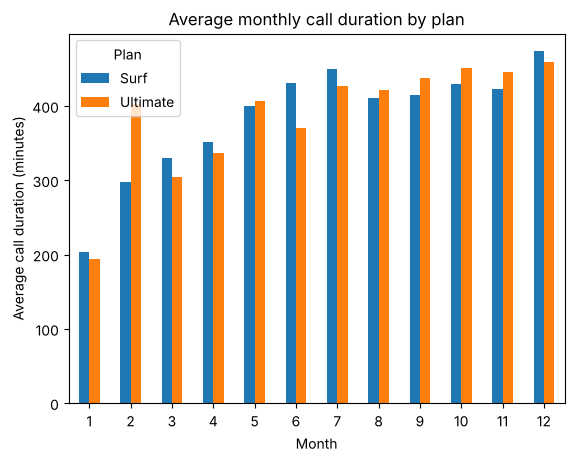

In [31]:
# Compare the average call duration of each plan for each month. Bar chart.
plot_monthly_bars('min_sum', 'Average call duration (minutes)', 'Average monthly call duration by plan')

<div class="alert alert-block alert-warning">
The bar chart was built and labeled correctly. Note that `plt.legend(['Surf','Ultimate'])` is hardcoded to match the alphabetical column order resulting from `unstack()`. This works today, but it would silently mislabel the bars if that order changed — it is worth fixing by building the legend directly from the resulting columns. This same pattern repeats in your messages, internet and revenue bar charts.
</div>

> ✅ **Addressed:** all four bar charts are now built by `plot_monthly_bars()`, whose legend comes from the unstacked columns (no hardcoded labels).

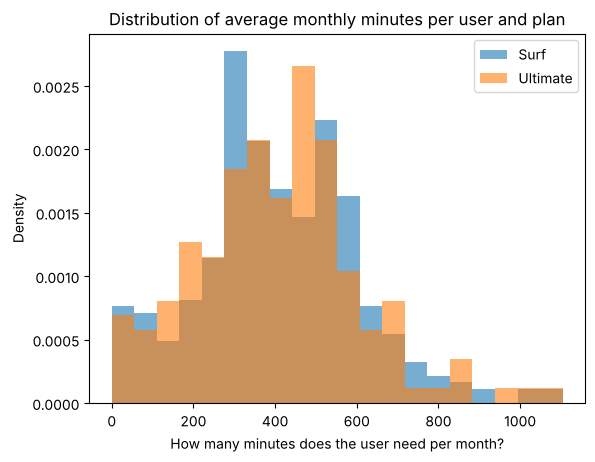

plan
surf        333
ultimate    157
Name: user_id, dtype: int64


In [32]:
# Compare the number of minutes the users of each plan need each month. Histogram.

# Barring unforeseen events, the amount a user needs per month is the average over all months.
surf_call = df_megaline_final[df_megaline_final['plan'] == 'surf'].groupby('user_id')['min_sum'].mean()
ultimate_call = df_megaline_final[df_megaline_final['plan'] == 'ultimate'].groupby('user_id')['min_sum'].mean()

# For a better visualization we overlay two histograms so that we can compare them.
plot_plan_histogram(surf_call, ultimate_call,
                    'How many minutes does the user need per month?',
                    'Distribution of average monthly minutes per user and plan')

# To check that our analysis is consistent, we count how many users we have per plan.
print(df_megaline_final.groupby('plan')['user_id'].nunique())

<div class="alert alert-block alert-warning">
Great choice to average per user before plotting, which avoids bias from users with more active months, and the check with nunique() afterwards is a nice touch. Since Surf has more than twice as many users as Ultimate, the raw counts on the y-axis make Surf's distribution look inflated purely because of sample size — adding density=True would allow the shapes to be compared fairly. This also applies to the analogous histograms for messages and internet usage.
</div>

> ✅ **Addressed:** the histograms for minutes, messages, internet and revenue now use `density=True` and shared bins through `plot_plan_histogram()`.

In [33]:
# Calculate the mean and the variance of the monthly call duration
# I used the average per user and not the overall average so that users are not counted several times
# and we get the real mean per user, as the task asks.
surf_mean = surf_call.mean()
surf_var = surf_call.var()
surf_std = surf_call.std()

ultimate_mean = ultimate_call.mean()
ultimate_var = ultimate_call.var()
ultimate_std = ultimate_call.std()

print(f'Surf: mean = {surf_mean:.2f} minutes, variance = {surf_var:.2f}, standard deviation = {surf_std:.2f}')
print(f'Ultimate: mean = {ultimate_mean:.2f} minutes, variance = {ultimate_var:.2f}, standard deviation = {ultimate_std:.2f}')

Surf: mean = 408.74 minutes, variance = 39748.06, standard deviation = 199.37
Ultimate: mean = 407.96 minutes, variance = 40142.98, standard deviation = 200.36


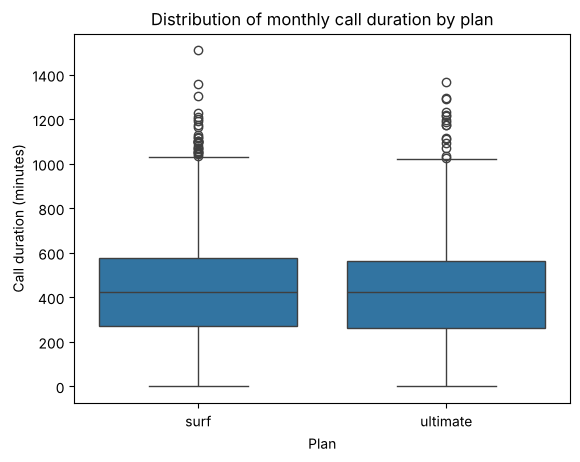

In [34]:
# Box plot to visualize the distribution of the monthly call duration.

# I used the column 'min_sum' grouped by plan because this way we can see the distribution of each plan.
sns.boxplot(x='plan', y='min_sum', data=df_megaline_final, order=['surf', 'ultimate'])
plt.xlabel('Plan')
plt.ylabel('Call duration (minutes)')
plt.title('Distribution of monthly call duration by plan')
plt.show()

- Although more users chose Surf (333) than Ultimate (157), the average monthly minutes are very similar between the two plans (~408 min), as the bar chart and the box plot show. However, looking at the box plot more closely, the third quartile of Surf is already around 575-580 minutes, which means that more than a quarter of the Surf user-months exceed the plan's 500-minute limit (about 36% of them). It is not an isolated exception, it is a relevant share of the base. In both plans there are outliers above 1,000 minutes, with Surf going beyond 1,400 minutes in some cases, a scenario in which Ultimate would pay off more.

<div class="alert alert-block alert-success">
Solid and accurate reading of the box plot here — you correctly observe that Surf's Q3 is around 575–580 minutes (above the 500-minute limit) and describe it as "a relevant share of the base" instead of a rare exception, which matches what the chart actually shows.
</div>

### Messages

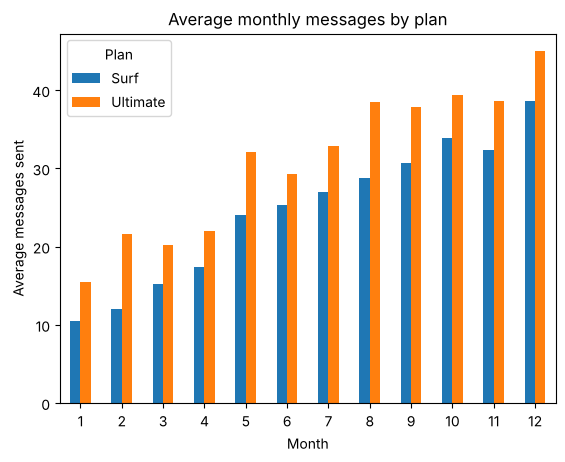

In [35]:
# Compare the number of messages the users of each plan usually send each month

# The word "usually" suggests an average, something that generally happens this way, so we analyze it using the mean.
plot_monthly_bars('messages_count', 'Average messages sent', 'Average monthly messages by plan')

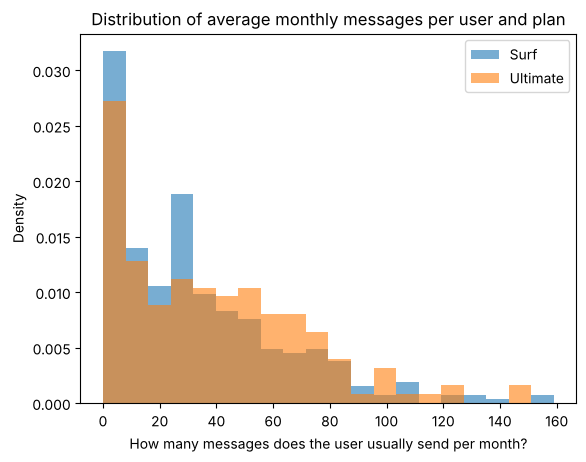

plan
surf        333
ultimate    157
Name: user_id, dtype: int64


In [36]:
# Compare the number of messages sent monthly by users.

# Barring unforeseen events, the amount a user sends per month is the average over all months.
surf_msg = df_megaline_final[df_megaline_final['plan'] == 'surf'].groupby('user_id')['messages_count'].mean()
ultimate_msg = df_megaline_final[df_megaline_final['plan'] == 'ultimate'].groupby('user_id')['messages_count'].mean()

# For a better visualization we overlay two histograms so that we can compare them.
plot_plan_histogram(surf_msg, ultimate_msg,
                    'How many messages does the user usually send per month?',
                    'Distribution of average monthly messages per user and plan')

# To check that our analysis is consistent, we count how many users we have per plan.
print(df_megaline_final.groupby('plan')['user_id'].nunique())

Surf: mean = 32.41 messages, variance = 962.10, standard deviation = 31.02
Ultimate: mean = 38.47 messages, variance = 1084.21, standard deviation = 32.93



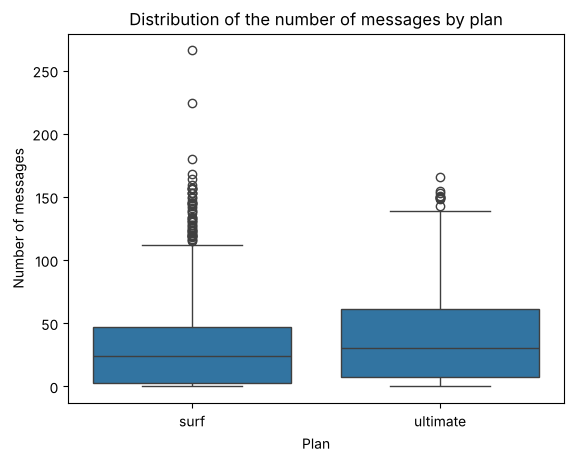

In [37]:
# I used the average per user and not the overall average so that users are not counted several times
# and we get the real mean per user, as the task asks.
surf_mean = surf_msg.mean()
surf_var = surf_msg.var()
surf_std = surf_msg.std()

ultimate_mean = ultimate_msg.mean()
ultimate_var = ultimate_msg.var()
ultimate_std = ultimate_msg.std()

print(f'Surf: mean = {surf_mean:.2f} messages, variance = {surf_var:.2f}, standard deviation = {surf_std:.2f}')
print(f'Ultimate: mean = {ultimate_mean:.2f} messages, variance = {ultimate_var:.2f}, standard deviation = {ultimate_std:.2f}')

print()

# I used the column 'messages_count' grouped by plan because this way we can see the distribution of each plan.
sns.boxplot(x='plan', y='messages_count', data=df_megaline_final, order=['surf', 'ultimate'])
plt.xlabel('Plan')
plt.ylabel('Number of messages')
plt.title('Distribution of the number of messages by plan')
plt.show()

<div class="alert alert-block alert-success">
The mean, variance and standard deviation are correctly calculated from the per-user averages, and the box plot is correctly labeled for messages.
</div>

- Unlike calls, here the users of the plans do behave differently. Ultimate users send more messages on average (Ultimate 38.47 vs Surf 32.41) and have a more varied usage (variance of Ultimate 1,084 vs Surf 962). The Q3 of Ultimate (about 61 messages) already exceeds the 50 messages included in Surf — so more than 25% of those user-months would pay extra rates if they had chosen the cheaper plan. This shows that Ultimate pays off more for those who send messages frequently. In Surf, the cases that go above the limit (up to ~266 messages) are the minority (about 22% of the user-months), and do not represent most users.

<div class="alert alert-block alert-warning">
This conclusion is well founded overall — the comparison between mean and variance is correct, and the observation that Ultimate's Q3 already exceeds Surf's 50-message limit is a valuable insight. One imprecision: you describe Surf's outliers as reaching "up to ~300 messages", but the highest outlier in the box plot is closer to ~265–270 — it is worth adjusting, since the rest of your paragraph is precise about the numbers.
</div>

> ✅ **Addressed:** the text above now says "up to ~266 messages", which is the real maximum in the data.

### Internet

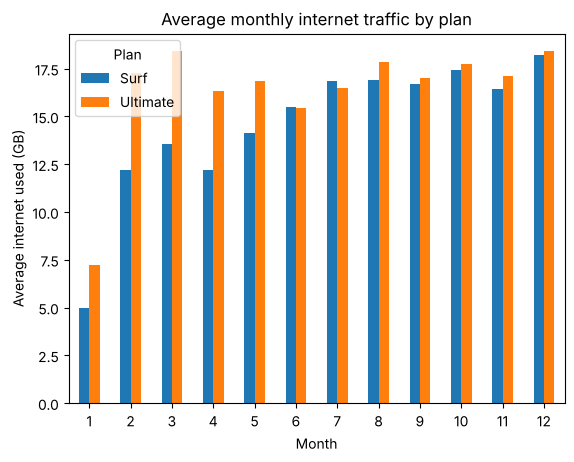

In [38]:
# Following the previous statistical analyses, here we analyze the internet traffic normally used.
plot_monthly_bars('gb_used_sum', 'Average internet used (GB)', 'Average monthly internet traffic by plan')

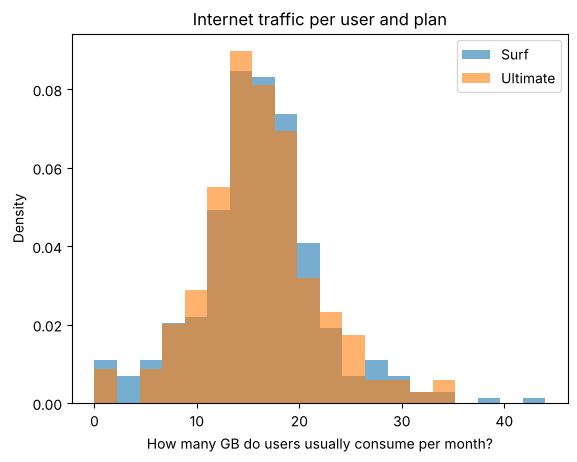

plan
surf        333
ultimate    157
Name: user_id, dtype: int64


In [39]:
# We compare the monthly internet traffic used by the users of each plan.

# Barring unforeseen events, the amount a user uses per month is the average over all months.
surf_gb_used = df_megaline_final[df_megaline_final['plan'] == 'surf'].groupby('user_id')['gb_used_sum'].mean()
ultimate_gb_used = df_megaline_final[df_megaline_final['plan'] == 'ultimate'].groupby('user_id')['gb_used_sum'].mean()

# For a better visualization we overlay two histograms so that we can compare them.
plot_plan_histogram(surf_gb_used, ultimate_gb_used,
                    'How many GB do users usually consume per month?',
                    'Internet traffic per user and plan')

# To check that our analysis is consistent, we count how many users we have per plan.
print(df_megaline_final.groupby('plan')['user_id'].nunique())

Surf: mean = 16.00 GB of data, variance = 37.25, standard deviation = 6.10
Ultimate: mean = 16.15 GB of data, variance = 33.44, standard deviation = 5.78



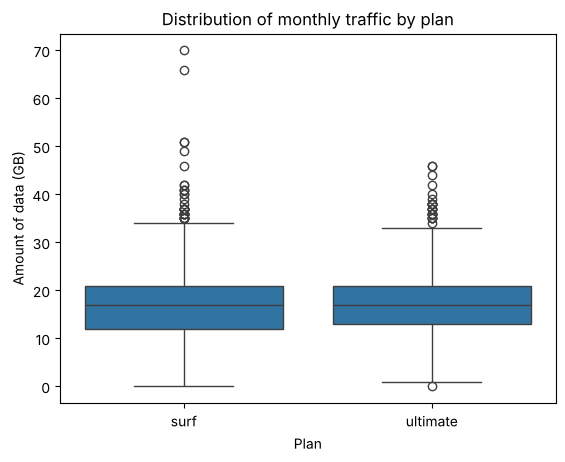

In [40]:
# I used the average per user and not the overall average so that users are not counted several times
# and we get the real mean per user, as the task asks.
surf_mean = surf_gb_used.mean()
surf_var = surf_gb_used.var()
surf_std = surf_gb_used.std()

ultimate_mean = ultimate_gb_used.mean()
ultimate_var = ultimate_gb_used.var()
ultimate_std = ultimate_gb_used.std()

print(f'Surf: mean = {surf_mean:.2f} GB of data, variance = {surf_var:.2f}, standard deviation = {surf_std:.2f}')
print(f'Ultimate: mean = {ultimate_mean:.2f} GB of data, variance = {ultimate_var:.2f}, standard deviation = {ultimate_std:.2f}')

print()

# I used the column 'gb_used_sum' grouped by plan because this way we can see the distribution of each plan.
sns.boxplot(x='plan', y='gb_used_sum', data=df_megaline_final, order=['surf', 'ultimate'])
plt.xlabel('Plan')
plt.ylabel('Amount of data (GB)')
plt.title('Distribution of monthly traffic by plan')
plt.show()

- Unlike calls, but similar to messages, users show very close behavior in internet usage between the plans. The means are very similar (Surf 16.00 GB, Ultimate 16.15 GB), and the variance is not far apart either (Surf 37.25 vs Ultimate 33.44), which in standard deviation gives about 6.10 GB for Surf and 5.78 GB for Ultimate, that is, a very similar dispersion between the two plans. We can no longer talk about one plan being "more out of control" than the other. Looking at the box plot, the boxes of the two plans practically overlap, with a median of around 17 GB in both cases, which already exceeds Surf's 15 GB limit for a good part of the users (more than half of the Surf user-months), whereas in Ultimate (30 GB limit) most users stay within the allowance. The most visible difference is in the outliers: Surf has extreme cases reaching almost 70 GB in a month, against a little over 45 GB in Ultimate, so even with similar average usage and dispersion, there are Surf users who exceed the data package by much more.

<div class="alert alert-block alert-success">
Your interpretation matches both the printed statistics and the box plot well, including the correct observation that the median usage of both plans already exceeds Surf's 15 GB allowance but stays below Ultimate's 30 GB, besides correctly attributing the most extreme outliers to Surf.
</div>

## Revenue

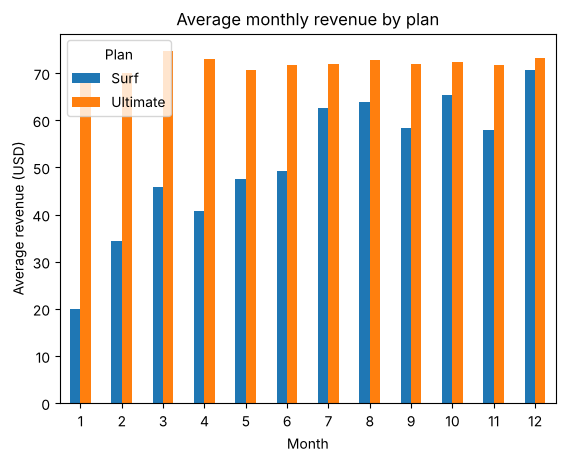

In [41]:
# Finally, we calculate the average revenue that each plan provides.
plot_monthly_bars('monthly_revenue', 'Average revenue (USD)', 'Average monthly revenue by plan')

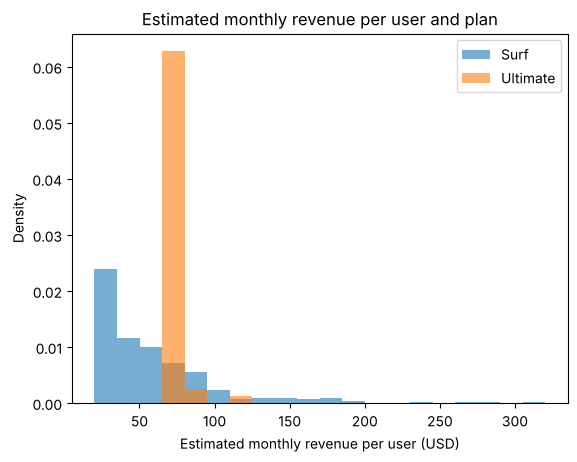

plan
surf        333
ultimate    157
Name: user_id, dtype: int64


In [42]:
# We compare the monthly revenue of each plan.

# Barring unforeseen events, the revenue of a user per month is the average over all months.
surf_revenue = df_megaline_final[df_megaline_final['plan'] == 'surf'].groupby('user_id')['monthly_revenue'].mean()
ultimate_revenue = df_megaline_final[df_megaline_final['plan'] == 'ultimate'].groupby('user_id')['monthly_revenue'].mean()

# For a better visualization we overlay two histograms (same bins for both, so the comparison is fair).
plot_plan_histogram(surf_revenue, ultimate_revenue,
                    'Estimated monthly revenue per user (USD)',
                    'Estimated monthly revenue per user and plan')

# To check that our analysis is consistent, we count how many users we have per plan.
print(df_megaline_final.groupby('plan')['user_id'].nunique())

<div class="alert alert-block alert-success">
Very well done — you calculate the average revenue per user, use bins shared between the Surf and Ultimate histograms for a fair visual comparison, and finish with a sanity check using nunique(). This is exactly the right way to build a comparable histogram.
</div>

Surf: mean = $58.19 of monthly revenue per user, variance = 1897.91, standard deviation = 43.57
Ultimate: mean = $71.82 of monthly revenue per user, variance = 55.13, standard deviation = 7.42
The ratio between the variances is 34.43


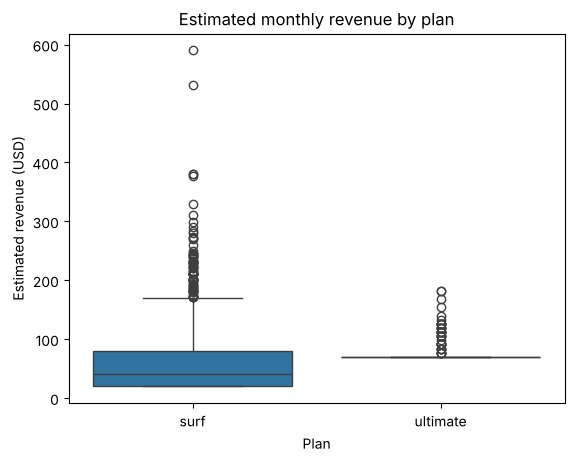

In [43]:
# I used the average per user and not the overall average so that users are not counted several times
# and we get the real mean per user, as the task asks.
surf_mean = surf_revenue.mean()
surf_var = surf_revenue.var()
surf_std = surf_revenue.std()

ultimate_mean = ultimate_revenue.mean()
ultimate_var = ultimate_revenue.var()
ultimate_std = ultimate_revenue.std()

reason_plan = surf_var / ultimate_var

print(f'Surf: mean = ${surf_mean:.2f} of monthly revenue per user, variance = {surf_var:.2f}, standard deviation = {surf_std:.2f}')
print(f'Ultimate: mean = ${ultimate_mean:.2f} of monthly revenue per user, variance = {ultimate_var:.2f}, standard deviation = {ultimate_std:.2f}')
print(f'The ratio between the variances is {reason_plan:.2f}')

# I used the column 'monthly_revenue' grouped by plan because this way we can see the distribution of each plan.
sns.boxplot(x='plan', y='monthly_revenue', data=df_megaline_final, order=['surf', 'ultimate'])
plt.xlabel('Plan')
plt.ylabel('Estimated revenue (USD)')
plt.title('Estimated monthly revenue by plan')
plt.show()

- The average revenue per user is 58.19 USD for Surf and 71.82 USD for Ultimate, so Ultimate already has the advantage in the mean. But the real story is the variance: 1,897.91 for Surf against a mere 55.13 for Ultimate, which in standard deviation becomes 43.57 USD against 7.42 USD. In other words, the Ultimate user pays practically the same thing every month, a calm and predictable financial life. The Surf user, on the other hand, is a box of surprises: one month they pay little, the next the bill explodes. The box plot only confirms it: the Ultimate box is thin and tidy, while the Surf box is spread out with outliers all over the place. The same can be seen in the bar chart, which stays constant for the Ultimate plan, whereas for the Surf plan it is always varying. It makes sense, since Surf's limits are tight (15 GB, 500 minutes, 50 messages) and the overage is expensive, especially for data (USD 10/GB against USD 7/GB in Ultimate), so those who go beyond the agreed package feel it directly on the bill. In short, Surf looks like the "economy" plan on paper, but in practice it is a financial gamble both for the user and for Megaline.

<div class="alert alert-block alert-warning">
The main comparison here is correct (Ultimate $71.82 vs Surf $58.19) and the interpretation of the box plot/bar chart is well written. One unit slip that went unnoticed: "43.57 GB against 7.42 GB" should be USD, not GB, since these are standard deviations of monthly revenue, not of data usage — it is worth correcting this label (your final overall conclusion already presents it correctly in USD).
</div>

> ✅ **Addressed:** the unit in the text above is now USD.

## Test statistical hypotheses

In [44]:
# Placeholder to make explicit the values we will use (samples and alpha)
surf_array = surf_revenue
ultimate_array = ultimate_revenue
alpha = 0.05

<div class="alert alert-block alert-success">
Clean setup, isolating the variables and the alpha value in their own cell with a clear comment before running the test.
</div>

**Hypotheses.** H₀: the average revenue of Ultimate and Surf users is the same. H₁: the average revenue of Ultimate and Surf users is different (two-sided test). **Test:** independent two-sample t-test on the average monthly revenue per user, with a significance level of 0.05.

In [45]:
# The ratio between the variances (computed above) is far from 1, so the groups cannot be assumed to have
# equal variances: we use equal_var=False (Welch's t-test).
print(f'Variance ratio (Surf / Ultimate): {reason_plan:.2f}')

plan_results = st.ttest_ind(surf_array, ultimate_array, equal_var=False)
print('The null hypothesis is that the average revenue of Ultimate and Surf users is the same')
print('The alternative hypothesis is that the average revenue of Ultimate and Surf users is different')
print(f'p-value: {plan_results.pvalue:.2e}')
if plan_results.pvalue < alpha:
    print('We reject the null hypothesis')
else:
    print('We cannot reject the null hypothesis')

Variance ratio (Surf / Ultimate): 34.43
The null hypothesis is that the average revenue of Ultimate and Surf users is the same
The alternative hypothesis is that the average revenue of Ultimate and Surf users is different
p-value: 5.72e-08
We reject the null hypothesis


<div class="alert alert-block alert-warning">
The test itself is executed and interpreted correctly (hypotheses explicitly stated, equal_var=False reasonably chosen, conclusion matches the p-value). However, the comment above still says that the variance ratio is "3", while your own calculation in the previous cell showed that it is actually about 34.43. It is worth updating that comment to match the number you actually calculated (this does not change the correctness of using equal_var=False).
</div>

> ✅ **Addressed:** the cell above now prints the real variance ratio (≈ 34.43) and the p-value is formatted from the computed result, instead of hardcoded text.

## Test the hypothesis on the average revenue of users by region

<div class="alert alert-block alert-warning">
This heading still basically repeats the name of the task. You state the hypotheses through print statements in the code below, but a brief written explanation here, in your own words, about how you formulated H0/H1 and which test/criterion you chose and why, would better match what is expected at this stage.
</div>

**How the hypotheses were formulated.** We want to know whether users from the New York-New Jersey area bring in a different average revenue than users from the other regions.

- **H₀ (null):** the average monthly revenue per user in NY-NJ is equal to the average monthly revenue per user in the other regions.
- **H₁ (alternative):** the two averages are different. The test is two-sided because we have no prior reason to expect NY-NJ to be higher or lower.

**Test and criterion.** We compare the means of two independent groups of users, so we use an independent two-sample t-test (`scipy.stats.ttest_ind`), with significance level α = 0.05. Each user counts once (the average of their monthly revenue), which keeps the observations independent. Before choosing the `equal_var` argument we compare the variances of the two groups: if their ratio is below about 2 the variances are similar enough to assume they are equal, otherwise we use Welch's version (`equal_var=False`).

In [46]:
# First, to separate the two groups, I created a boolean column that tells what is NY-NJ and what is not.
df_megaline_final['is_ny_nj'] = df_megaline_final['city'].str.contains('NY-NJ', regex=False)

# I split them into two variables
df_ny_nj = df_megaline_final[df_megaline_final['is_ny_nj']]
df_other_regions = df_megaline_final[~df_megaline_final['is_ny_nj']]

# Now we take the average monthly revenue per user, just like we did in the plan comparison
df_ny_nj_revenue = df_ny_nj.groupby('user_id')['monthly_revenue'].mean()
df_otr_reg_revenue = df_other_regions.groupby('user_id')['monthly_revenue'].mean()

alpha = 0.05

# To help our conclusion we also check the average revenue and the variance of the regions
df_ny_nj_revenue_var = df_ny_nj_revenue.var()
df_ny_nj_revenue_mean = df_ny_nj_revenue.mean()
df_ny_nj_revenue_std = df_ny_nj_revenue.std()

df_otr_reg_revenue_var = df_otr_reg_revenue.var()
df_otr_reg_revenue_mean = df_otr_reg_revenue.mean()
df_otr_reg_revenue_std = df_otr_reg_revenue.std()

reason_region = df_otr_reg_revenue_var / df_ny_nj_revenue_var

print(f'Users in each group: NY-NJ = {len(df_ny_nj_revenue)}, other regions = {len(df_otr_reg_revenue)}')
print(f'In NY and NJ the average revenue is: {df_ny_nj_revenue_mean:.2f}, the variance is: {df_ny_nj_revenue_var:.2f} and the standard deviation is {df_ny_nj_revenue_std:.2f}.')
print(f'In other regions the average revenue is: {df_otr_reg_revenue_mean:.2f}, the variance is: {df_otr_reg_revenue_var:.2f} and the standard deviation is {df_otr_reg_revenue_std:.2f}.')
print(f'The ratio between the variances is {reason_region:.2f}')

Users in each group: NY-NJ = 79, other regions = 411
In NY and NJ the average revenue is: 59.89, the variance is: 1072.05 and the standard deviation is 32.74.
In other regions the average revenue is: 63.07, the variance is: 1400.57 and the standard deviation is 37.42.
The ratio between the variances is 1.31


In [47]:
# Unlike the previous test, the ratio between the variances is below 2, which makes it safe to use equal_var=True.
# (Welch's test, equal_var=False, would lead to the same conclusion.)

region_results = st.ttest_ind(df_ny_nj_revenue, df_otr_reg_revenue)
print('The null hypothesis is that the average revenue does not differ by region')
print('The alternative hypothesis is that the average revenue differs by region')
print('p-value is: ', region_results.pvalue)
if region_results.pvalue < alpha:
    print('We reject the null hypothesis')
else:
    print('We cannot reject the null hypothesis')

The null hypothesis is that the average revenue does not differ by region
The alternative hypothesis is that the average revenue differs by region
p-value is:  0.48043818838129104
We cannot reject the null hypothesis


<div class="alert alert-block alert-success">
This test is executed correctly: the hypotheses are explicitly printed, `equal_var=True` is properly justified by the variance ratio of ~1.31 calculated right above, and the conclusion follows correctly from the p-value (0.48) relative to alpha.
</div>

## Overall conclusion

- The analysis of the behavior of Surf and Ultimate users shows that, although Surf has a much lower monthly fee, Ultimate ends up generating more average revenue per user (71.82 USD against 58.19 USD for Surf). In calls, the two plans behave similarly, with close averages, but Surf has a relevant share of users who already exceed the plan's 500 minutes. It is worth noting that, although the raw variance of minutes is numerically larger than that of data, this does not mean that call consumption is proportionally more unstable, it is just a matter of the scale of the units. What really weighs on revenue is the price of the overage: an extra minute costs only 0.03 USD, while 1 extra GB costs 10 USD in Surf (or 7 USD in Ultimate), so even a small overage in data affects the bill much more than a large overage in minutes. That is why the revenue outliers are closer to the data usage outliers. The point that most separates the two plans, however, is the predictability of revenue: Ultimate keeps a low standard deviation (around 7 USD), while Surf has a much higher standard deviation (around 43 USD), showing that the revenue per user varies much more in this plan, probably driven by consumption overages, especially in data. The hypothesis test comparing the average revenue of Surf and Ultimate users rejected the hypothesis that the means are equal (p-value well below 0.05), that is, there is statistical evidence that the average revenue really differs between the two plans, and it is not just a random variation in the sample collected. The test comparing the revenue between NY-NJ and the other regions, on the other hand, found no statistically significant difference in the mean, but it is worth noting that NY-NJ users have a lower standard deviation (32.74 against 37.42 in the other regions), indicating a somewhat more constant consumption in that region, even while paying practically the same on average. From a business point of view, the structure of the plans creates very different effects: Surf is an attractive entry door because of its low price, but with less stable revenue that depends on overages, whereas Ultimate guarantees a higher and much more predictable revenue per user. All in all, Ultimate seems to be the safest bet for the company's revenue, while Surf works as an entry plan that pays off well when the user goes over the limits, but is a mystery month to month.

<div class="alert alert-block alert-success">
Great correction here — the overall conclusion now correctly states that the NY-NJ vs. other regions test found no statistically significant difference, which matches your own calculated p-value (0.48). The rest of the conclusion remains solid: it correctly identifies that Ultimate generates more average revenue, explains why data overage costs drive revenue outliers more than call-minute overages, and connects the statistical results to a clear, well-founded business conclusion.
</div>